# 4.2 Partición y preprocesamiento

En esta sección cargamos la partición definida en el análisis exploratorio, verificamos la ausencia de fuga de información y calculamos con el conjunto de entrenamiento las estadísticas de normalización y los pesos de clase.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from src import config as C
from src import plots as P
from src.persist import is_done, load_pickle, save_pickle

P.setup()
C.ensure_dirs()
pd.set_option("display.precision", 4)
print("Resultados:", C.RESULTS.name, "| modelos:", ", ".join(C.MODELS))

Resultados: results | modelos: CNN, MobileNetV2, ResNet-18


## Partición

Usamos la partición de la sección 2.4: sin las 6 imágenes con etiqueta contradictoria, con los casi-duplicados agrupados y cada grupo asignado completo a una sola partición, en proporción 5:1:1 (≈ 71/14/14 %). Antes de cada corrida se verifica la huella SHA-256 del conjunto de prueba.

La selección de hiperparámetros usa una partición fija de validación. La validación cruzada anidada multiplicaría el costo computacional por el número de pliegues y no fue viable con los recursos disponibles; en consecuencia, la configuración elegida puede ajustarse en parte a las 360 imágenes de validación.

In [2]:
from src.data import prepare_common

common = prepare_common()
sp, norm, cw = common["splits"], common["norm"], common["class_weights"]

conteos = pd.DataFrame({s: np.bincount(sp[s]["y"], minlength=C.NUM_CLASSES) for s in ("train", "val", "test")},
                       index=C.CLASSES)
conteos["total"] = conteos.sum(axis=1)
conteos.loc["total"] = conteos.sum()
proporcion = (conteos.iloc[:-1, :3] / conteos.iloc[:-1, :3].sum() * 100).round(1)
display(conteos)
display(proporcion.rename(columns=lambda c: f"{c} (%)"))

,train,val,test,total
cardboard,287,58,58,403
glass,355,71,72,498
metal,292,59,58,409
paper,424,85,85,594
plastic,343,68,69,480
trash,99,19,19,137
total,1800,360,361,2521


,train (%),val (%),test (%)
cardboard,15.9,16.1,16.1
glass,19.7,19.7,19.9
metal,16.2,16.4,16.1
paper,23.6,23.6,23.5
plastic,19.1,18.9,19.1
trash,5.5,5.3,5.3


In [3]:
pares = [("train", "val"), ("train", "test"), ("val", "test")]
verif = pd.DataFrame({
    "archivos idénticos (SHA-256) compartidos": [len(set(sp[a]["sha256"]) & set(sp[b]["sha256"])) for a, b in pares],
    "grupos de casi-duplicados compartidos": [len(set(sp[a]["group"]) & set(sp[b]["group"])) for a, b in pares],
}, index=[f"{a} / {b}" for a, b in pares])
display(verif)
assert verif.to_numpy().sum() == 0, "Hay solapamiento entre particiones"
print("Huella del test:", sp["test_fingerprint"][:16], "... coincide con la registrada en el EDA")

,archivos idénticos (SHA-256) compartidos,grupos de casi-duplicados compartidos
train / val,0,0
train / test,0,0
val / test,0,0


Huella del test: 4e4651dc5c8bbbfc ... coincide con la registrada en el EDA


## Redimensionamiento y normalización

Redimensionamos las imágenes de 512×384 a 224×224 con interpolación bicúbica. Descartamos el *letterbox* (relleno hasta un cuadrado) porque añade franjas que actuarían como fondo artificial, y el fondo ya está asociado a la clase (sección 2.7). La deformación de 4:3 a 1:1 es la misma para todas las imágenes y para los tres modelos.

Calculamos la media y la desviación estándar por canal con el conjunto de entrenamiento redimensionado y las comparamos con las obtenidas a resolución original.

In [4]:
import json

eda = json.loads((ROOT / "data" / "splits" / "norm_stats_v2_s1234.json").read_text(encoding="utf-8"))
tabla_norm = pd.DataFrame({"media 512×384 (EDA)": eda["mean"], "DE 512×384 (EDA)": eda["std"],
                           "media 224×224": norm["mean"], "DE 224×224": norm["std"]}, index=["R", "G", "B"])
display(tabla_norm)

,media 512×384 (EDA),DE 512×384 (EDA),media 224×224,DE 224×224
R,0.6718,0.2105,0.6718,0.2091
G,0.6380,0.2107,0.6380,0.2093
B,0.6022,0.2322,0.6022,0.2309


## Pesos de clase

La pérdida es la entropía cruzada ponderada, $\mathcal L = -\sum_i w_{y_i}\log p(y_i\mid x_i) / \sum_i w_{y_i}$, con $w_k = N/(K\,n_k)$ calculado en entrenamiento. El promedio de los pesos es 1; una imagen de `trash` pesa unas cuatro veces más que una de `paper`.

In [5]:
tabla_pesos = pd.DataFrame({"imágenes en train": cw["counts_train"], "peso w_k": np.round(cw["weights"], 3)},
                           index=C.CLASSES)
display(tabla_pesos)

,imágenes en train,peso w_k
cardboard,287,1.045
glass,355,0.845
metal,292,1.027
paper,424,0.708
plastic,343,0.875
trash,99,3.030


## Aumento de datos

En entrenamiento aplicamos transformaciones que preservan la etiqueta: `RandomResizedCrop(224, scale=(0.7, 1.0))`, volteos horizontal y vertical, `RandomRotation(15)` y `ColorJitter(0.2, 0.2, 0.2, 0.02)`. La variación de brillo, contraste, saturación y tono responde al atajo de iluminación identificado en la sección 2.7; el recorte modifica la proporción de fondo visible. En validación y prueba solo se normaliza.

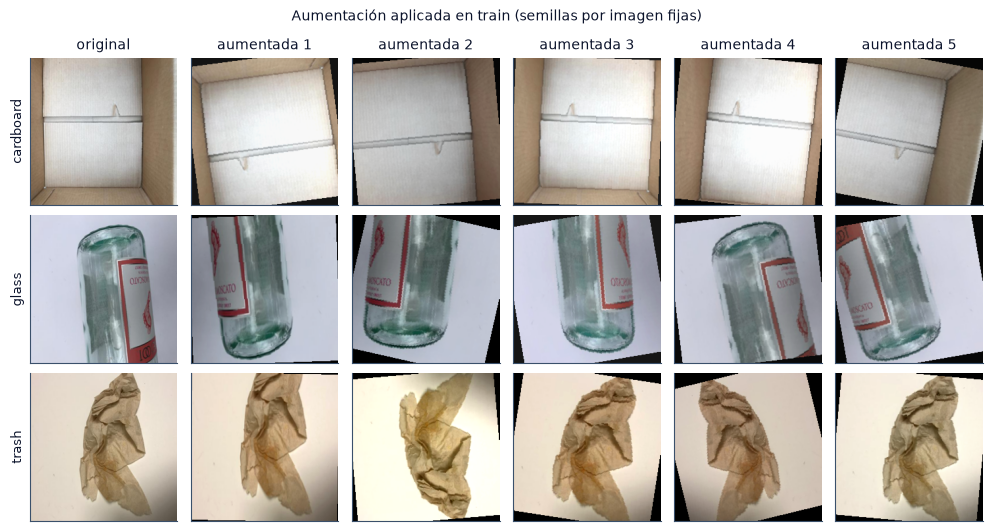

In [6]:
from src.data import CachedImages, load_cache, train_transform

cache = load_cache()
ds_vis = CachedImages(common["cache"], sp["train"]["rows"], sp["train"]["y"], train_transform([0, 0, 0], [1, 1, 1]))
ejemplos = [int(np.flatnonzero(sp["train"]["y"] == k)[3]) for k in (0, 1, 5)]
fig, ax = plt.subplots(3, 6, figsize=(10, 5.4))
datos = {}
for i, p in enumerate(ejemplos):
    ax[i, 0].imshow(cache[sp["train"]["rows"][p]])
    ax[i, 0].set_ylabel(C.CLASSES[sp["train"]["y"][p]])
    datos[sp["train"]["relpath"][p]] = []
    for j in range(1, 6):
        x, _, _ = ds_vis[(p, 1000 * j + p)]
        img = x.permute(1, 2, 0).clamp(0, 1).numpy()
        ax[i, j].imshow(img)
        datos[sp["train"]["relpath"][p]].append(1000 * j + p)
ax[0, 0].set_title("original")
for j in range(1, 6):
    ax[0, j].set_title(f"aumentada {j}")
for a in ax.flat:
    a.set_xticks([]); a.set_yticks([]); a.grid(False)
fig.suptitle("Aumentación aplicada en train (semillas por imagen fijas)", fontsize=10)
fig.tight_layout()
P.save(fig, "4_2_aumentacion", {"imagenes": list(datos), "semillas": datos})
plt.show()

## Conclusión

La partición no presenta archivos ni grupos de casi-duplicados compartidos entre entrenamiento, validación y prueba. La normalización y los pesos de clase se calcularon solo con entrenamiento. Las estadísticas a 224×224 son casi iguales a las de resolución original, con una desviación estándar ligeramente menor por el suavizado del redimensionamiento.